# 可选实验：线性回归的梯度下降

<figure>
    <center> <img src="./images/C1_W1_L4_S1_Lecture_GD.png"  style="width:800px;height:200px;" ></center>
</figure>


## 目标
在本实验中，你将：
- 使用梯度下降来自动优化 $w$ 和 $b$ 的过程。


## 工具
在本实验中，我们将使用：
- NumPy，一个常用的科学计算库
- Matplotlib，一个常用的数据绘图库
- 本地目录中 lab_utils.py 文件里的绘图例程


In [1]:
import math, copy
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')
from lab_utils_uni import plt_house_x, plt_contour_wgrad, plt_divergence, plt_gradients

<a name="toc_40291_2"></a>
# 问题描述

让我们沿用之前相同的两个数据点——一套 1000 平方英尺的房子以 \$300,000 售出，一套 2000 平方英尺的房子以 \$500,000 售出。

| 面积 (1000 sqft)     | 价格 (1000 美元) |
| ----------------| ------------------------ |
| 1               | 300                      |
| 2               | 500                      |


In [2]:
# 加载我们的数据集
x_train = np.array([1.0, 2.0])   #特征
y_train = np.array([300.0, 500.0])   #目标值


<a name="toc_40291_2.0.1"></a>
### 计算代价 (Compute_Cost)
这部分在上一个实验中已经开发过。这里我们还会再次用到它。


In [3]:
#计算代价的函数
def compute_cost(x, y, w, b):

    m = x.shape[0]
    cost = 0

    for i in range(m):
        f_wb = w * x[i] + b
        cost = cost + (f_wb - y[i])**2
    total_cost = 1 / (2 * m) * cost

    return total_cost


<a name="toc_40291_2.1"></a>
## 梯度下降概述
到目前为止，在本课程中，你已经开发了一个预测 $f_{w,b}(x^{(i)})$ 的线性模型：
$$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$
在线性回归中，你利用输入的训练数据，通过最小化预测值 $f_{w,b}(x^{(i)})$ 与实际数据 $y^{(i)}$ 之间误差的某种度量，来拟合参数 $w$、$b$。这个度量被称为 $cost$（代价），即 $J(w,b)$。在训练中，你会在所有训练样本 $x^{(i)},y^{(i)}$ 上度量代价
$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2\tag{2}$$



在讲课中，*梯度下降*（gradient descent）被描述为：

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$
其中，参数 $w$、$b$ 是同时更新的。
梯度定义为：
$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$

这里 *同时*（simultaniously）意味着在更新任何一个参数之前，先计算出所有参数的偏导数。


<a name="toc_40291_2.2"></a>
## 实现梯度下降
你将针对单个特征实现梯度下降算法。你需要三个函数。
- `compute_gradient`，实现上面的公式 (4) 和 (5)
- `compute_cost`，实现上面的公式 (2)（来自上一个实验的代码）
- `gradient_descent`，使用 compute_gradient 和 compute_cost

约定：
- 包含偏导数的 Python 变量命名遵循这样的模式，$\frac{\partial J(w,b)}{\partial b}$ 将命名为 `dj_db`。
- w.r.t 是 With Respect To（关于）的缩写，例如 $J(wb)$ 关于 $b$ 的偏导数。



<a name="toc_40291_2.3"></a>
### compute_gradient
<a name='ex-01'></a>
`compute_gradient` 实现上面的 (4) 和 (5)，并返回 $\frac{\partial J(w,b)}{\partial w}$、$\frac{\partial J(w,b)}{\partial b}$。内嵌的注释描述了相关操作。


In [4]:
def compute_gradient(x, y, w, b):
    """
    计算线性回归的梯度
    参数:
      x (ndarray (m,)): 数据，m 个样本
      y (ndarray (m,)): 目标值
      w,b (scalar)    : 模型参数
    返回
      dj_dw (scalar): 代价关于参数 w 的梯度
      dj_db (scalar): 代价关于参数 b 的梯度
     """

    # 训练样本数量
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_db += dj_db_i
        dj_dw += dj_dw_i
    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db


<br/>


<img align="left" src="./images/C1_W1_Lab03_lecture_slopes.PNG"   style="width:340px;" > 讲课中描述了梯度下降如何利用某一点处代价关于某参数的偏导数来更新该参数。
让我们使用 `compute_gradient` 函数来求出并绘制代价函数关于其中一个参数 $w_0$ 的一些偏导数。


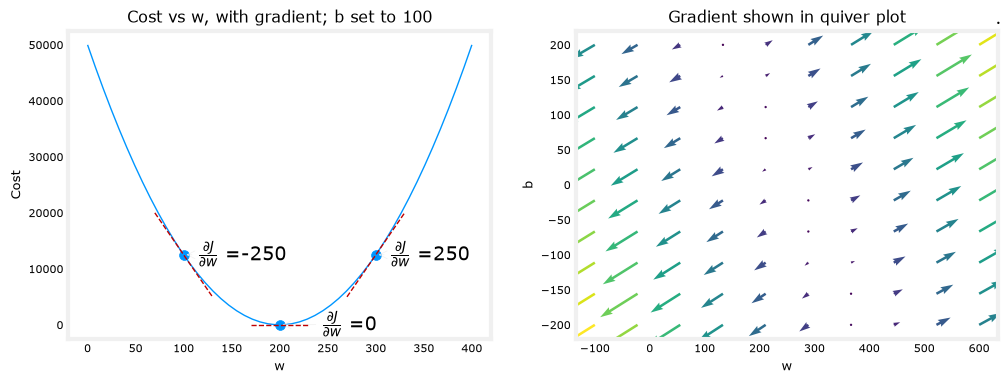

In [5]:
plt_gradients(x_train,y_train, compute_cost, compute_gradient)
plt.show()

在上方，左图展示了 $\frac{\partial J(w,b)}{\partial w}$，即代价曲线在三个点处相对于 $w$ 的斜率。在图的右侧，导数为正，而左侧为负。由于这种 '碗形'，导数总是会引导梯度下降走向底部，即梯度为零处。

左图中 $b=100$ 固定不变。梯度下降将同时利用 $\frac{\partial J(w,b)}{\partial w}$ 和 $\frac{\partial J(w,b)}{\partial b}$ 来更新参数。右侧的 '向量图'（quiver plot）提供了一种查看两个参数梯度的方法。箭头大小反映该点处梯度的大小。箭头的方向和斜率反映了该点处 $\frac{\partial J(w,b)}{\partial w}$ 与 $\frac{\partial J(w,b)}{\partial b}$ 的比值。
注意，梯度指向的是 *远离* 最小值的方向。回顾上面的公式 (3)。缩放后的梯度是从 $w$ 或 $b$ 的当前值中被 *减去* 的。这会使参数朝着减小代价的方向移动。


<a name="toc_40291_2.5"></a>
###  梯度下降
既然梯度可以计算了，上面公式 (3) 中描述的梯度下降就可以在下面的 `gradient_descent` 中实现。实现的细节在注释中描述。下面，你将使用这个函数在训练数据上找到 $w$ 和 $b$ 的最优值。


In [7]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    """
    执行梯度下降以拟合 w,b。通过以学习率 alpha 进行
    num_iters 次梯度步进来更新 w,b

    参数:
      x (ndarray (m,))  : 数据，m 个样本
      y (ndarray (m,))  : 目标值
      w_in,b_in (scalar): 模型参数的初始值
      alpha (float):     学习率
      num_iters (int):   运行梯度下降的迭代次数
      cost_function:     用于计算代价的函数
      gradient_function: 用于计算梯度的函数

    返回:
      w (scalar): 运行梯度下降后参数的更新值
      b (scalar): 运行梯度下降后参数的更新值
      J_history (List): 代价值的历史记录
      p_history (list): 参数的历史记录 [w,b]
      """

    w = copy.deepcopy(w_in) # 避免修改全局的 w_in
    # 一个数组，用于存储每次迭代的代价 J 和 w，主要供之后绘图使用
    J_history = []
    p_history = []
    b = b_in
    w = w_in

    for i in range(num_iters):
        # 使用 gradient_function 计算梯度并更新参数
        dj_dw, dj_db = gradient_function(x, y, w , b)

        # 使用上面的公式 (3) 更新参数
        b = b - alpha * dj_db
        w = w - alpha * dj_dw

        # 保存每次迭代的代价 J
        if i<100000:      # 防止资源耗尽
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])
        # 每隔 10 次迭代（或迭代次数少于 10 时按实际次数）打印一次代价
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")

    return w, b, J_history, p_history #返回 w 以及 J、w 的历史记录用于绘图


In [8]:
# 初始化参数
w_init = 0
b_init = 0
# 一些梯度下降的设置
iterations = 10000
tmp_alpha = 1.0e-2
# 运行梯度下降
w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha,
                                                    iterations, compute_cost, compute_gradient)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")


Iteration    0: Cost 7.93e+04  dj_dw: -6.500e+02, dj_db: -4.000e+02   w:  6.500e+00, b: 4.00000e+00
Iteration 1000: Cost 3.41e+00  dj_dw: -3.712e-01, dj_db:  6.007e-01   w:  1.949e+02, b: 1.08228e+02
Iteration 2000: Cost 7.93e-01  dj_dw: -1.789e-01, dj_db:  2.895e-01   w:  1.975e+02, b: 1.03966e+02
Iteration 3000: Cost 1.84e-01  dj_dw: -8.625e-02, dj_db:  1.396e-01   w:  1.988e+02, b: 1.01912e+02
Iteration 4000: Cost 4.28e-02  dj_dw: -4.158e-02, dj_db:  6.727e-02   w:  1.994e+02, b: 1.00922e+02
Iteration 5000: Cost 9.95e-03  dj_dw: -2.004e-02, dj_db:  3.243e-02   w:  1.997e+02, b: 1.00444e+02
Iteration 6000: Cost 2.31e-03  dj_dw: -9.660e-03, dj_db:  1.563e-02   w:  1.999e+02, b: 1.00214e+02
Iteration 7000: Cost 5.37e-04  dj_dw: -4.657e-03, dj_db:  7.535e-03   w:  1.999e+02, b: 1.00103e+02
Iteration 8000: Cost 1.25e-04  dj_dw: -2.245e-03, dj_db:  3.632e-03   w:  2.000e+02, b: 1.00050e+02
Iteration 9000: Cost 2.90e-05  dj_dw: -1.082e-03, dj_db:  1.751e-03   w:  2.000e+02, b: 1.00024e+02


<img align="left" src="./images/C1_W1_Lab03_lecture_learningrate.PNG"  style="width:340px; padding: 15px; " >
花点时间注意上面打印出的梯度下降过程的一些特征。

- 代价一开始很大，然后迅速下降，正如讲课幻灯片中所述。
- 偏导数 `dj_dw` 和 `dj_db` 也会变小，起初很快，之后变慢。正如讲课图中所展示的，当过程接近 '碗底' 时，由于该点处导数较小，进展会变慢。
- 尽管学习率 alpha 保持固定，进展仍会变慢


### 代价随梯度下降迭代次数的变化
代价随迭代次数变化的图是衡量梯度下降进展的有用指标。在成功的运行中，代价应当始终下降。代价在初期变化非常迅速，因此将初始下降和最终下降用不同的尺度绘制会很有帮助。在下面的图中，注意坐标轴上代价的尺度以及迭代步数。


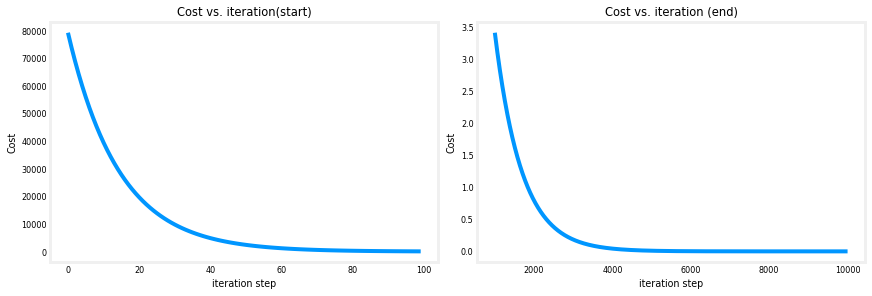

In [8]:
# 绘制代价随迭代次数变化的图
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12,4))
ax1.plot(J_hist[:100])
ax2.plot(1000 + np.arange(len(J_hist[1000:])), J_hist[1000:])
ax1.set_title("Cost vs. iteration(start)");  ax2.set_title("Cost vs. iteration (end)")
ax1.set_ylabel('Cost')            ;  ax2.set_ylabel('Cost')
ax1.set_xlabel('iteration step')  ;  ax2.set_xlabel('iteration step')
plt.show()


### 预测
既然你已经找到了参数 $w$ 和 $b$ 的最优值，现在就可以使用该模型基于我们学到的参数来预测房屋价值。正如预期的那样，对于相同的房屋，预测值与训练值几乎相同。此外，不在预测中的那个值也与期望值相符。


In [9]:
print(f"1000 sqft house prediction {w_final*1.0 + b_final:0.1f} Thousand dollars")
print(f"1200 sqft house prediction {w_final*1.2 + b_final:0.1f} Thousand dollars")
print(f"2000 sqft house prediction {w_final*2.0 + b_final:0.1f} Thousand dollars")


1000 sqft house prediction 300.0 Thousand dollars
1200 sqft house prediction 340.0 Thousand dollars
2000 sqft house prediction 500.0 Thousand dollars


<a name="toc_40291_2.6"></a>
## 绘图
你可以通过在 cost(w,b) 的等高线图上绘制代价随迭代次数的变化，来展示梯度下降在执行过程中的进展。


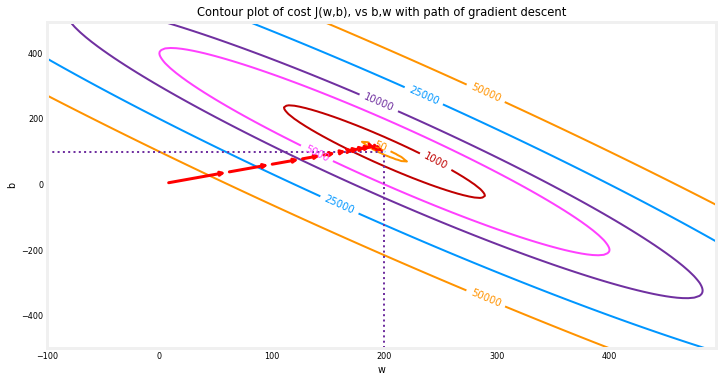

In [10]:
fig, ax = plt.subplots(1,1, figsize=(12, 6))
plt_contour_wgrad(x_train, y_train, p_hist, ax)

在上方，等高线图展示了在一定范围的 $w$ 和 $b$ 上 $cost(w,b)$ 的取值。代价水平由各个环表示。用红色箭头叠加显示的是梯度下降的路径。以下是几点需要注意的：
- 路径朝着目标稳步（单调）前进。
- 初始的步长比接近目标时的步长大得多。


**放大** 来看，我们可以看到梯度下降的最后几步。注意，随着梯度趋近于零，各步之间的距离在缩小。


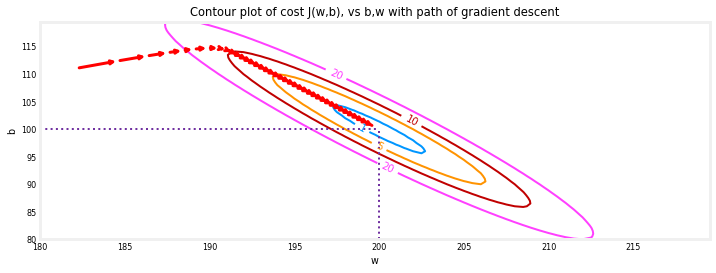

In [11]:
fig, ax = plt.subplots(1,1, figsize=(12, 4))
plt_contour_wgrad(x_train, y_train, p_hist, ax, w_range=[180, 220, 0.5], b_range=[80, 120, 0.5],
            contours=[1,5,10,20],resolution=0.5)

<a name="toc_40291_2.7.1"></a>
### 增大学习率

<figure>
 <img align="left", src="./images/C1_W1_Lab03_alpha_too_big.PNG"   style="width:340px;height:240px;" >
</figure>
在讲课中，讨论了公式 (3) 中学习率 $\alpha$ 的合适取值。$\alpha$ 越大，梯度下降收敛到解的速度越快。但是，如果它太大，梯度下降将会发散。上面你有一个能够很好收敛的解的例子。

让我们尝试增大 $\alpha$ 的值，看看会发生什么：


In [12]:
# 初始化参数
w_init = 0
b_init = 0
# 将 alpha 设为一个较大的值
iterations = 10
tmp_alpha = 8.0e-1
# 运行梯度下降
w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha,
                                                    iterations, compute_cost, compute_gradient)


Iteration    0: Cost 2.58e+05  dj_dw: -6.500e+02, dj_db: -4.000e+02   w:  5.200e+02, b: 3.20000e+02
Iteration    1: Cost 7.82e+05  dj_dw:  1.130e+03, dj_db:  7.000e+02   w: -3.840e+02, b:-2.40000e+02
Iteration    2: Cost 2.37e+06  dj_dw: -1.970e+03, dj_db: -1.216e+03   w:  1.192e+03, b: 7.32800e+02
Iteration    3: Cost 7.19e+06  dj_dw:  3.429e+03, dj_db:  2.121e+03   w: -1.551e+03, b:-9.63840e+02
Iteration    4: Cost 2.18e+07  dj_dw: -5.974e+03, dj_db: -3.691e+03   w:  3.228e+03, b: 1.98886e+03
Iteration    5: Cost 6.62e+07  dj_dw:  1.040e+04, dj_db:  6.431e+03   w: -5.095e+03, b:-3.15579e+03
Iteration    6: Cost 2.01e+08  dj_dw: -1.812e+04, dj_db: -1.120e+04   w:  9.402e+03, b: 5.80237e+03
Iteration    7: Cost 6.09e+08  dj_dw:  3.156e+04, dj_db:  1.950e+04   w: -1.584e+04, b:-9.80139e+03
Iteration    8: Cost 1.85e+09  dj_dw: -5.496e+04, dj_db: -3.397e+04   w:  2.813e+04, b: 1.73730e+04
Iteration    9: Cost 5.60e+09  dj_dw:  9.572e+04, dj_db:  5.916e+04   w: -4.845e+04, b:-2.99567e+04


在上方，$w$ 和 $b$ 在正值和负值之间来回震荡，且绝对值随每次迭代不断增大。此外，每次迭代 $\frac{\partial J(w,b)}{\partial w}$ 都会改变符号，代价不是在下降而是在上升。这是 *学习率过大* 且解正在发散的明显迹象。
让我们用一张图来可视化这一现象。


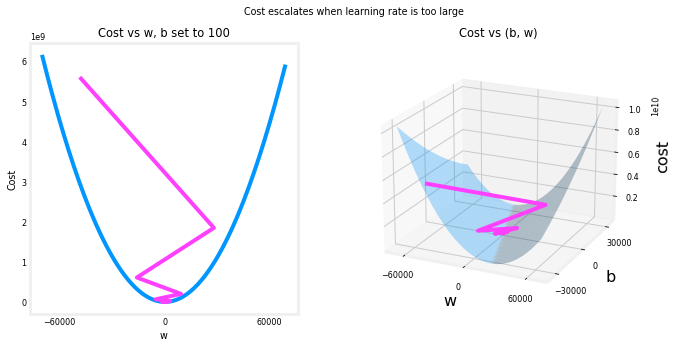

In [13]:
plt_divergence(p_hist, J_hist,x_train, y_train)
plt.show()

在上方，左图展示了 $w$ 在梯度下降最初几步中的变化过程。$w$ 在正负之间震荡，代价迅速增长。梯度下降同时在 $w$ 和 $b$ 上运行，因此需要右图的 3-D 图才能看到完整的画面。



## 恭喜！
在本实验中你：
- 深入了解了单变量梯度下降的细节。
- 开发了一个计算梯度的例程
- 可视化地了解了梯度是什么
- 完成了一个梯度下降例程
- 利用梯度下降来寻找参数
- 考察了学习率取值大小的影响
